# 03 — Time-Aware Validation, Horizon Error Diagnostics & vCore Capacity Policy
This notebook inspects the 4-fold expanding rolling-origin splits, examines learned inner-CV ensemble weights (`hybrid_ensemble_weights`), compares Top-Down vs. Bottom-Up Stratum reconciliation across `13` strata, analyzes holdout error decay across horizons (`h=1..24`), and evaluates operational capacity headroom policies across all **`28,396` provisioned fleet vCores**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from cwfc.io import load_cpu_readings, load_vm_metadata
from cwfc.predict import build_fleet_targets, prepare_training_frame
from cwfc.targets import split_train_holdout
from cwfc.validation import rolling_origin_splits
from cwfc.models import hybrid_ensemble_weights

DATA_DIR = Path('../challenge_data')
TABLES_DIR = Path('../reports/tables')
readings = load_cpu_readings(DATA_DIR)
metadata = load_vm_metadata(DATA_DIR)
agg_df = build_fleet_targets(readings)
train_df, holdout_df = split_train_holdout(agg_df, n_holdout=24)
train_prep = prepare_training_frame(train_df)

# Verify expanding rolling-origin CV splits and inner ensemble weights
splits = rolling_origin_splits(train_df, horizon=24, min_train_size=48, step=12)
split_rows = [{
    'fold': i + 1,
    'train_rows': sp.train_end_idx,
    'train_time_s': f"{int(train_df['timestamp'].iloc[0])}..{int(train_df['timestamp'].iloc[sp.train_end_idx - 1])}",
    'val_time_s': f"{int(train_df['timestamp'].iloc[sp.val_start_idx])}..{int(train_df['timestamp'].iloc[sp.val_end_idx - 1])}",
} for i, sp in enumerate(splits)]
print('=== 4 Expanding Rolling-Origin CV Folds ===')
display(pd.DataFrame(split_rows))

weight_rows = []
for t_col in ['fleet_avg_cpu', 'fleet_p95_max_cpu', 'fleet_busy_vm_fraction']:
    w = hybrid_ensemble_weights(train_prep, t_col)
    weight_rows.append({'target': t_col, **w})
print('=== Learned Inner-Backtest Hybrid Ensemble Weights (Full 110-Step Train) ===')
display(pd.DataFrame(weight_rows).round(4))

=== 4 Expanding Rolling-Origin CV Folds ===


,fold,train_rows,train_time_s,val_time_s
0,1,48,0..14100,14400..21300
1,2,60,0..17700,18000..24900
2,3,72,0..21300,21600..28500
3,4,84,0..24900,25200..32100


=== Learned Inner-Backtest Hybrid Ensemble Weights (Full 110-Step Train) ===


,target,persistence,moving_average_6,damped_ets,direct_ridge
0,fleet_avg_cpu,0.3192,0.2359,0.2402,0.2047
1,fleet_p95_max_cpu,0.3542,0.2844,0.2947,0.0666
2,fleet_busy_vm_fraction,0.2713,0.2527,0.2718,0.2042


,target,model_label,family,cv_mae_mean,cv_mae_std,cv_rmse_mean,holdout_mae,holdout_rmse,holdout_smape,holdout_nmae,holdout_mase,holdout_peak_mae
0,fleet_avg_cpu,Persistence,Baseline,0.2445,0.0868,0.2807,0.1468,0.1848,1.5851,1.0000,1.2119,0.4714
1,fleet_avg_cpu,Seasonal Naive,Baseline,0.3111,0.0326,0.3517,0.1464,0.1671,1.5787,0.9974,1.2087,0.1934
2,fleet_avg_cpu,MA(12),Baseline,0.2468,0.1182,0.2764,0.1230,0.1613,1.3263,0.8380,1.0156,0.4196
3,fleet_avg_cpu,Drift,Baseline,0.2780,0.1447,0.3140,0.1820,0.2206,1.9709,1.2402,1.5030,0.5244
4,fleet_avg_cpu,EWMA,Baseline,0.2553,0.0936,0.2906,0.1392,0.1770,1.5027,0.9485,1.1495,0.4570
5,fleet_avg_cpu,Damped ETS,Candidate,0.2847,0.1149,0.3224,0.1567,0.1941,1.6928,1.0672,1.2934,0.4864
6,fleet_avg_cpu,Direct Ridge,Candidate,0.3499,0.2228,0.3969,0.1455,0.1663,1.5604,0.9912,1.2012,0.0648
7,fleet_avg_cpu,Direct HGB,Candidate,0.2842,0.1113,0.3188,0.1195,0.1408,1.2872,0.8142,0.9867,0.1918
8,fleet_avg_cpu,Hybrid Ensemble,Candidate,0.2027,0.0880,0.2362,0.1061,0.1423,1.1430,0.7229,0.8761,0.3856
9,fleet_p95_max_cpu,Persistence,Baseline,2.9144,2.0183,3.4377,0.8270,1.0247,1.2669,1.0000,0.7402,2.0466


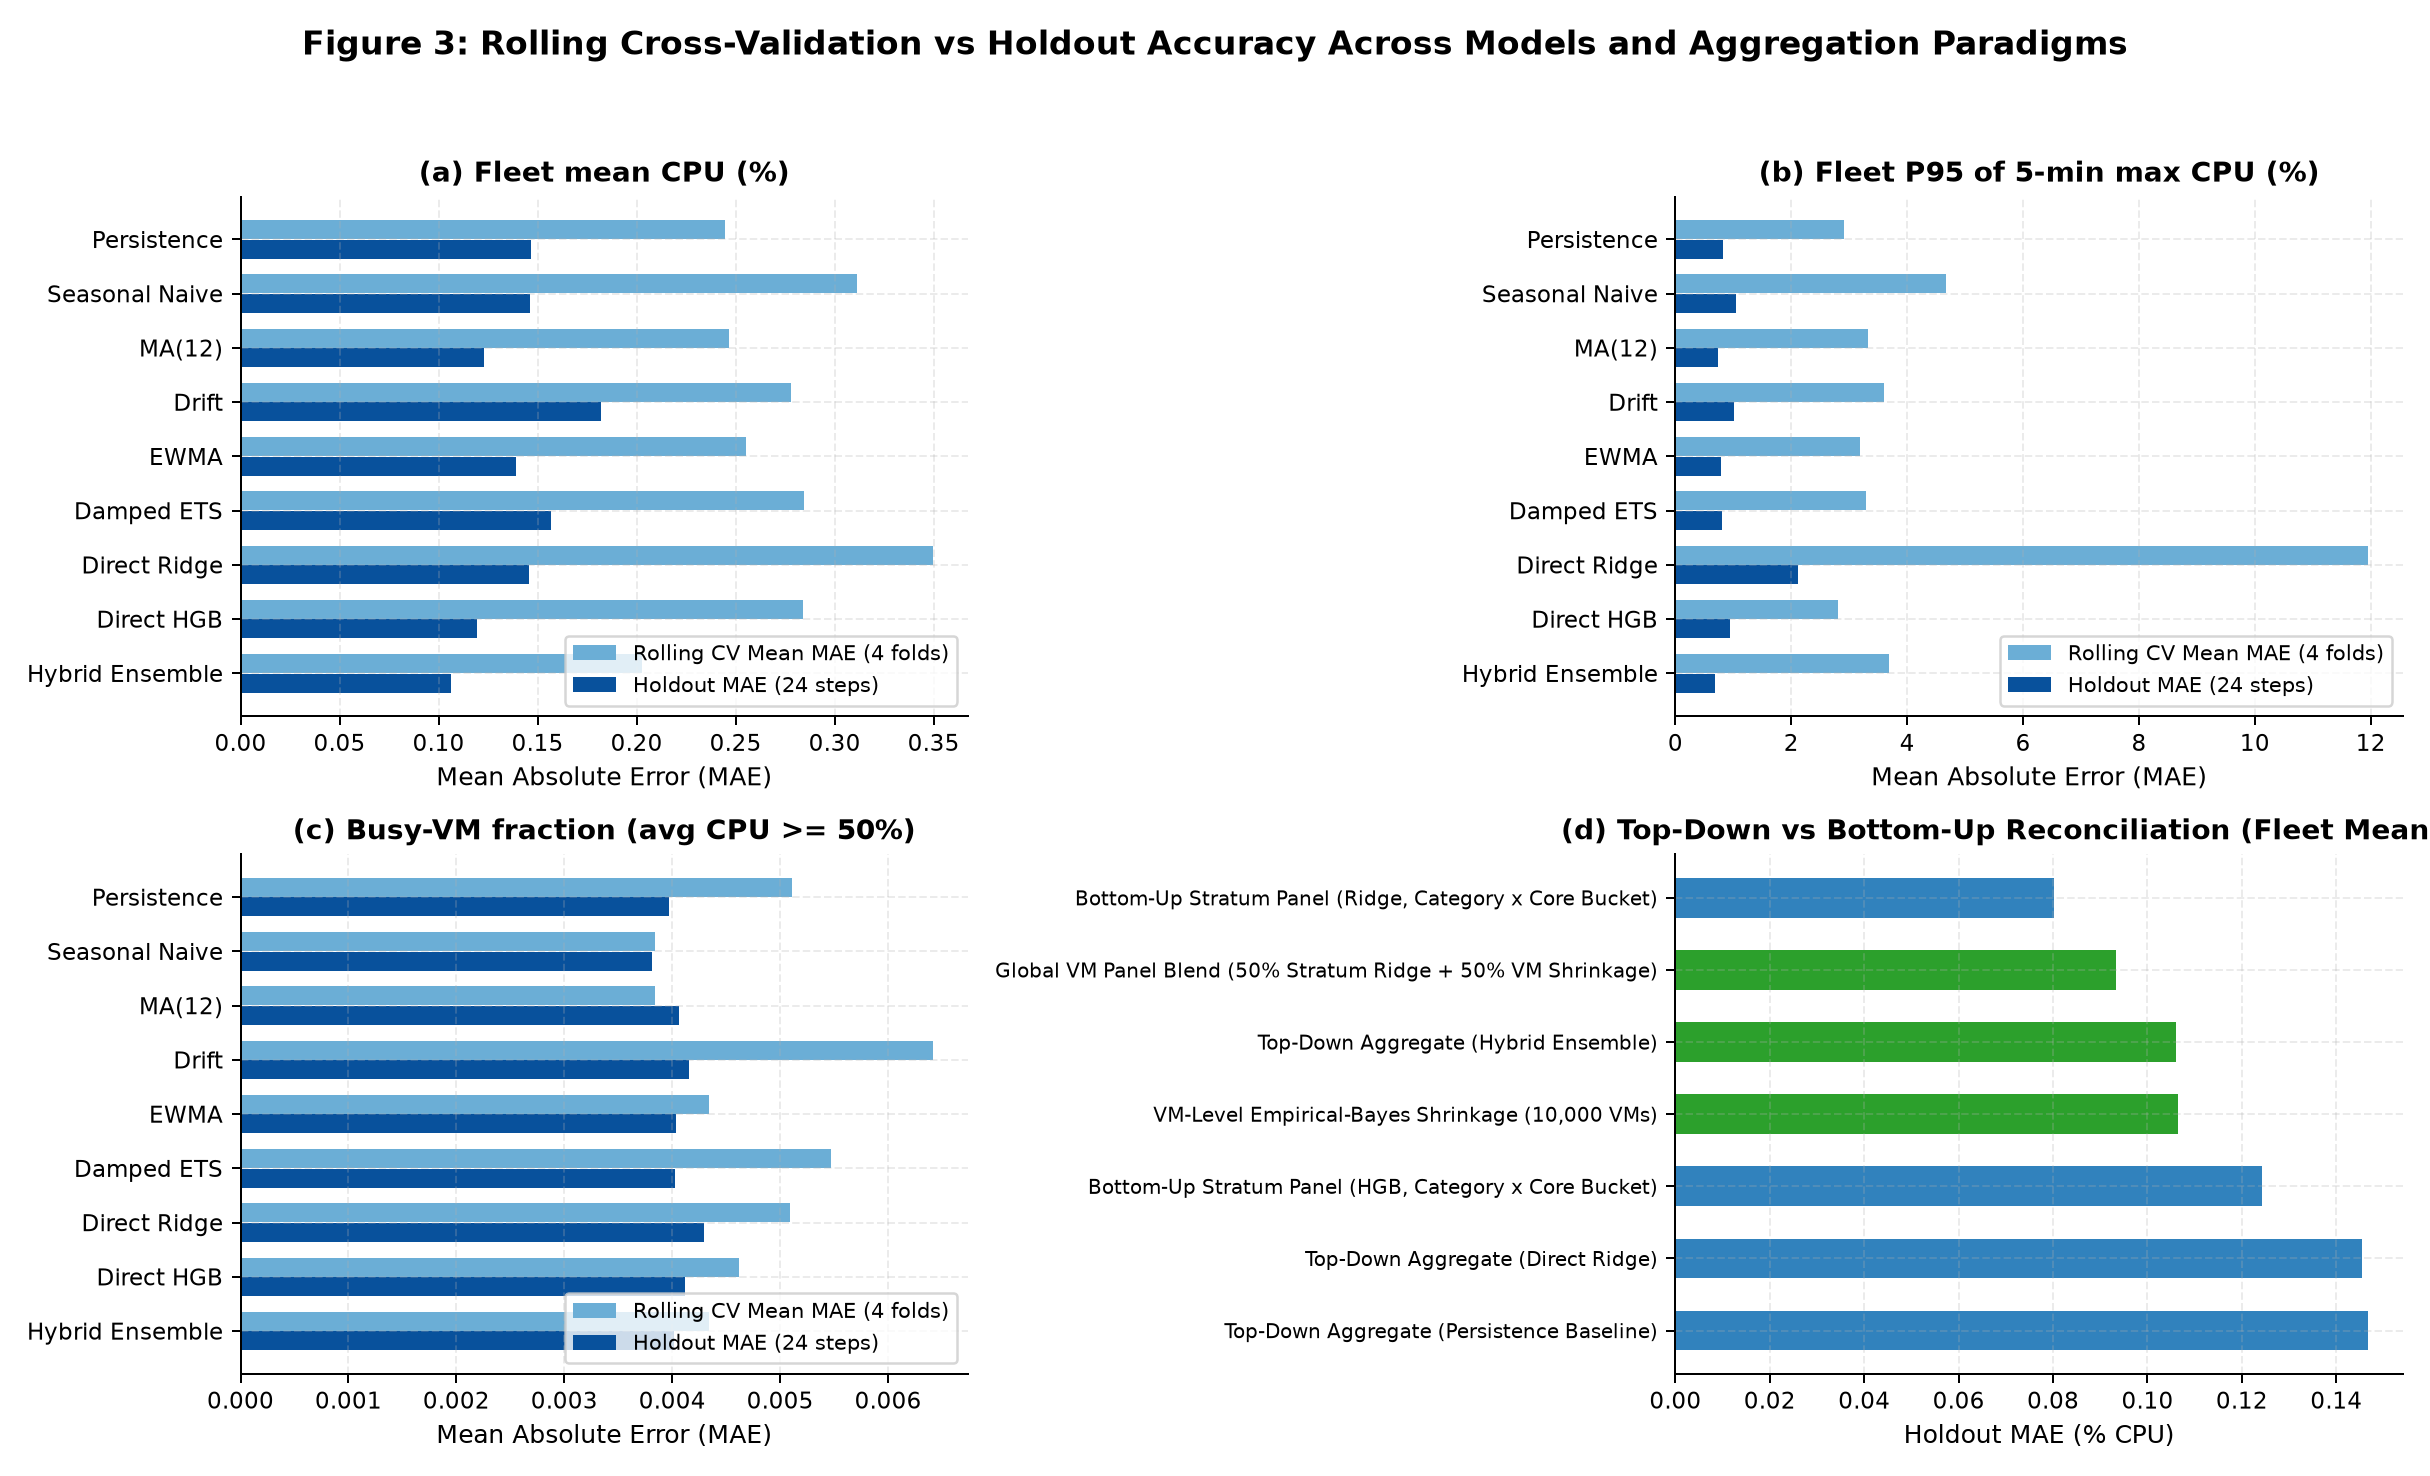

In [2]:
# Compare 4-Fold Rolling CV vs 24-Step Holdout Metrics
cv_df = pd.read_csv(TABLES_DIR / 'aggregate_cv_metrics.csv')
ho_df = pd.read_csv(TABLES_DIR / 'aggregate_holdout_metrics.csv')
merged = pd.merge(
    cv_df[['target', 'model_label', 'family', 'cv_mae_mean', 'cv_mae_std', 'cv_rmse_mean']],
    ho_df[['target', 'model_label', 'holdout_mae', 'holdout_rmse', 'holdout_smape', 'holdout_nmae', 'holdout_mase', 'holdout_peak_mae']],
    on=['target', 'model_label']
)
display(merged.round(4))
display(Image(filename='../reports/figures/fig3_cv_and_holdout_model_comparison.png'))

=== Top-Down vs Bottom-Up Reconciliation (fleet_avg_cpu) ===

,approach,paradigm,holdout_mae,holdout_rmse,holdout_smape,holdout_nmae,holdout_mase
3,"Bottom-Up Stratum Panel (Ridge, Category x Cor...",Segment Bottom-Up,0.0802,0.0980,0.8646,0.5462,0.6620
6,Global VM Panel Blend (50% Stratum Ridge + 50%...,Hierarchical Reconciliation,0.0934,0.1150,1.0067,0.6361,0.7709
2,Top-Down Aggregate (Hybrid Ensemble),Aggregate Top-Down,0.1061,0.1423,1.1430,0.7229,0.8761
5,"VM-Level Empirical-Bayes Shrinkage (10,000 VMs)",VM-Level Bottom-Up,0.1066,0.1343,1.1488,0.7260,0.8799
4,"Bottom-Up Stratum Panel (HGB, Category x Core ...",Segment Bottom-Up,0.1243,0.1515,1.3396,0.8466,1.0260
1,Top-Down Aggregate (Direct Ridge),Aggregate Top-Down,0.1455,0.1663,1.5604,0.9912,1.2012
0,Top-Down Aggregate (Persistence Baseline),Aggregate Top-Down,0.1468,0.1848,1.5851,1.0000,1.2119


=== Horizon Error Decay (fleet_avg_cpu) ===


horizon_bucket,"Full Holdout (h=1..24, 5-120m)","Long (h=13..24, 65-120m)","Medium (h=7..12, 35-60m)","Short (h=1..6, 5-30m)"
model_label,,,,
Damped ETS,0.1567,0.2210,0.0848,0.0997
Direct HGB,0.1195,0.1083,0.1171,0.1442
Direct Ridge,0.1455,0.1505,0.1606,0.1204
Hybrid Ensemble,0.1061,0.1365,0.0426,0.1089
MA(12),0.1230,0.1543,0.0468,0.1366
Persistence,0.1468,0.2060,0.0717,0.1034


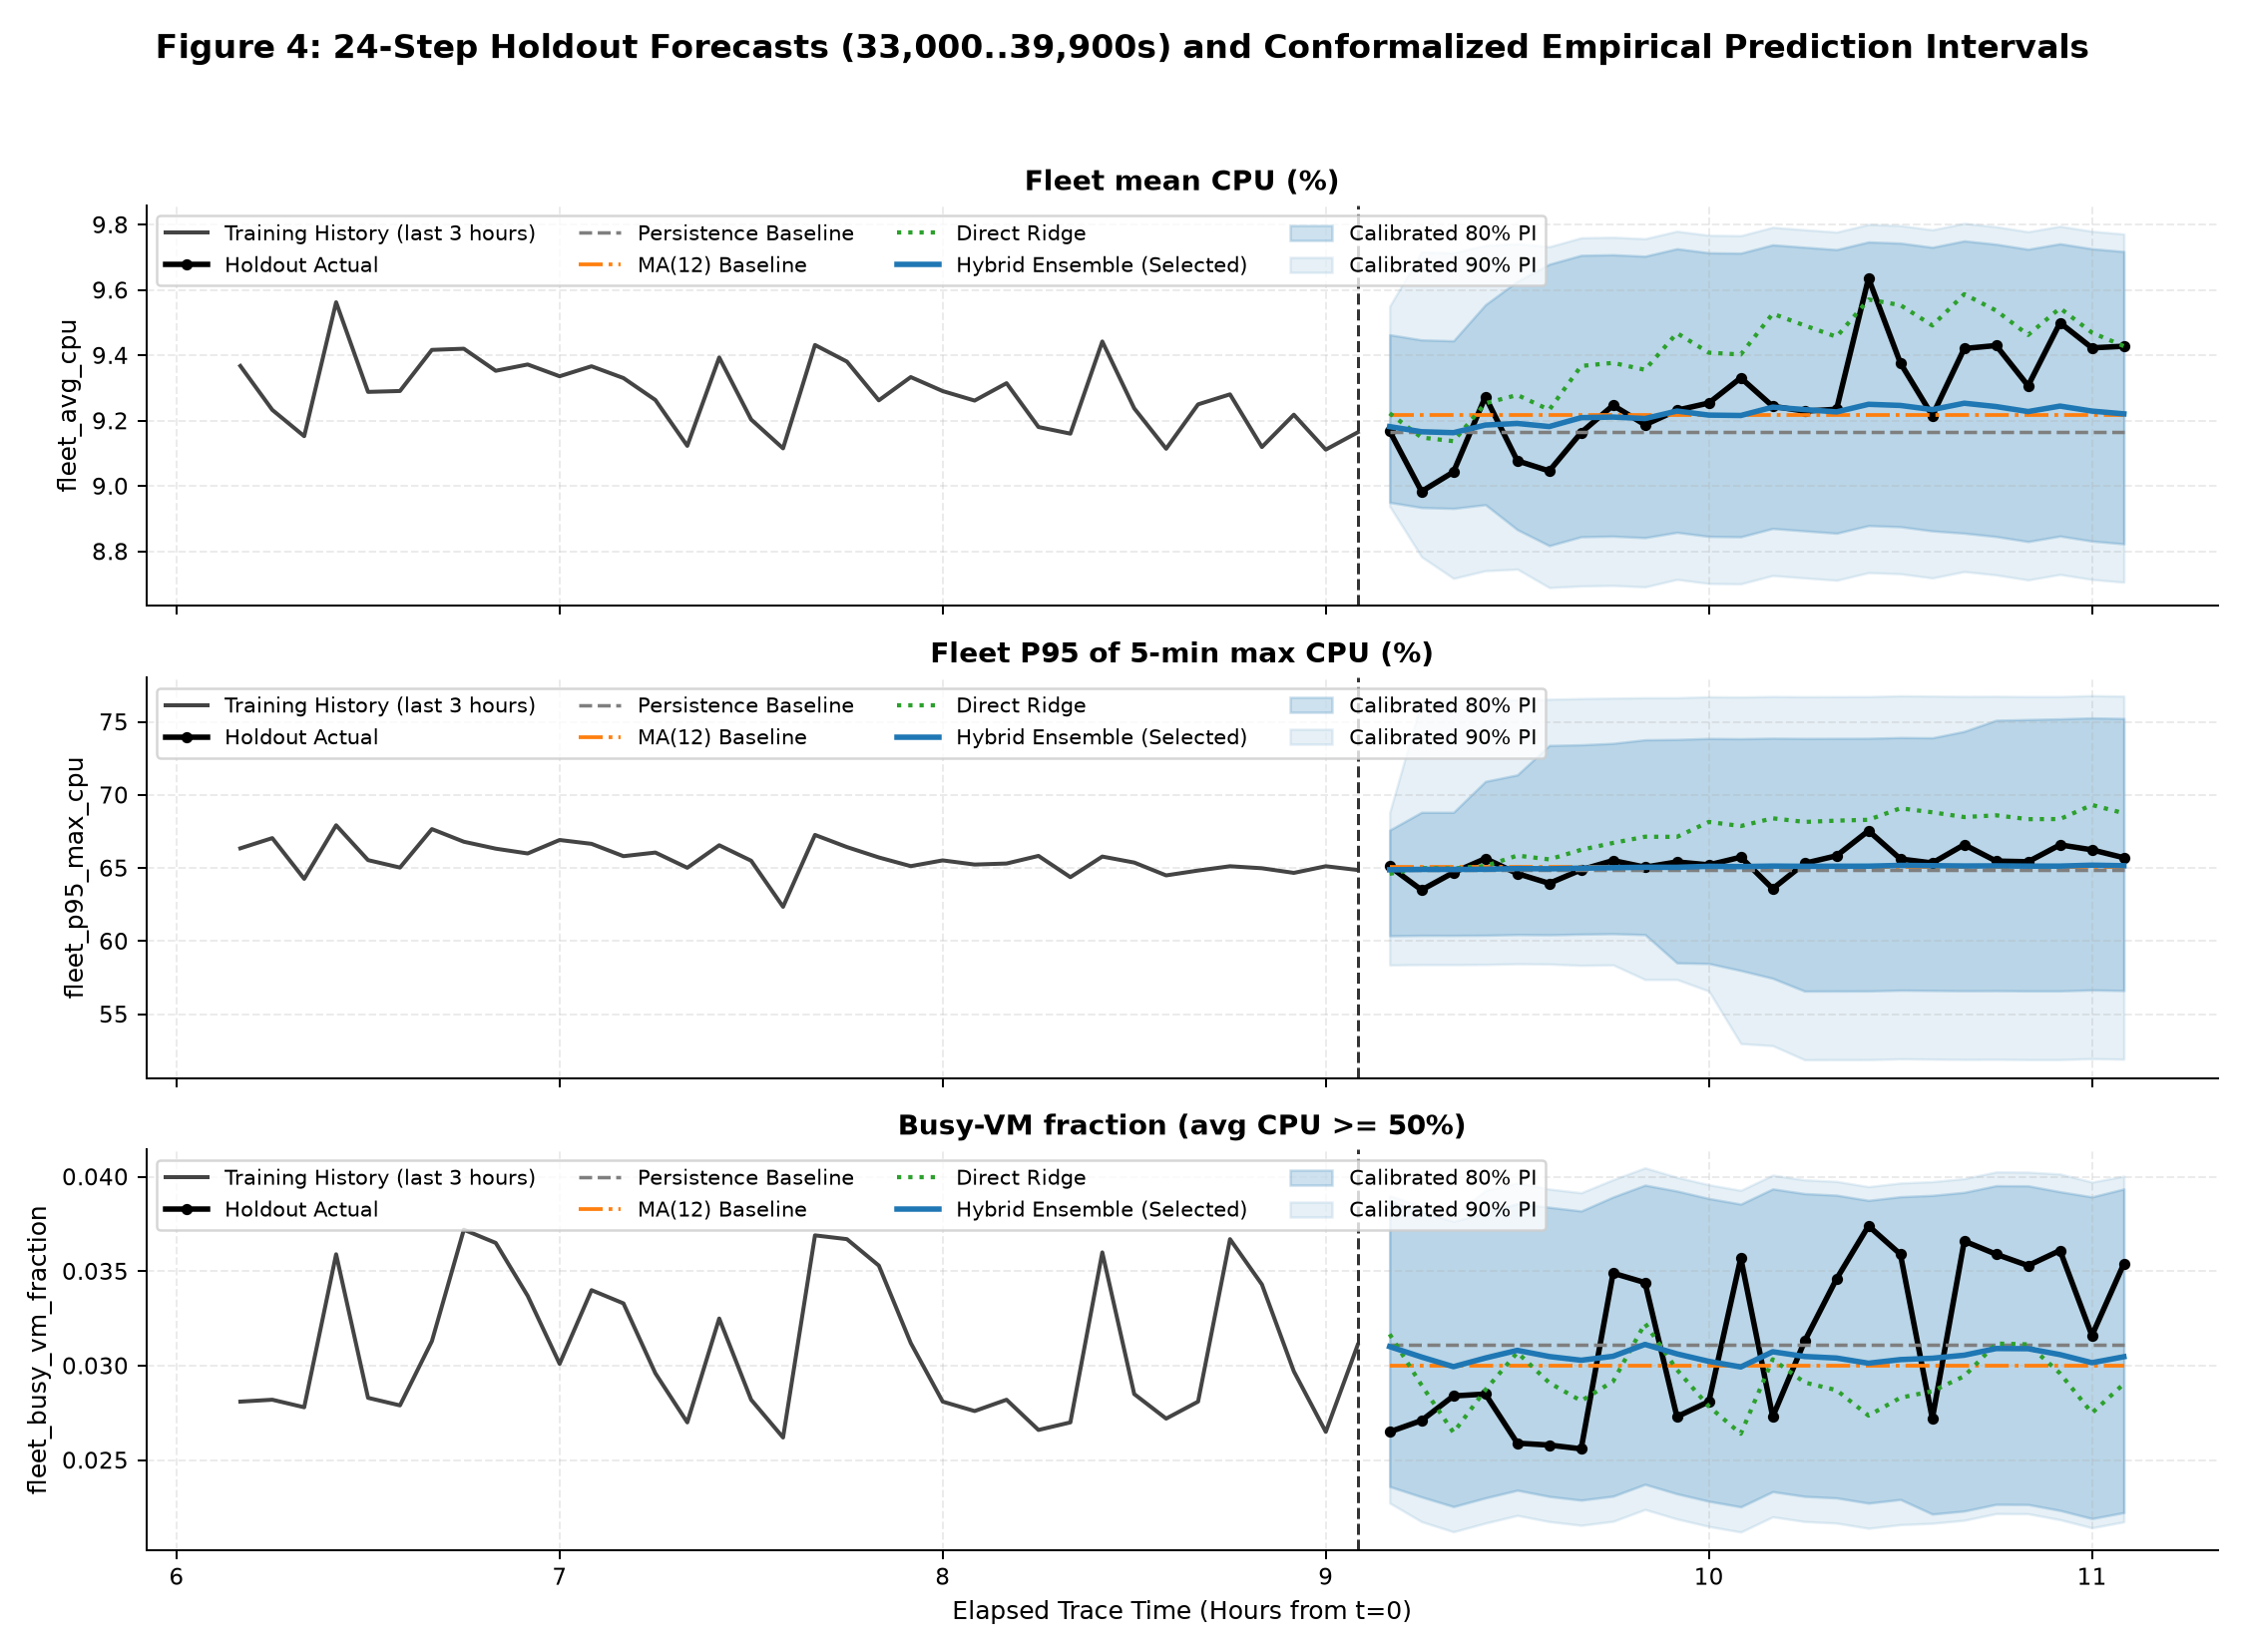

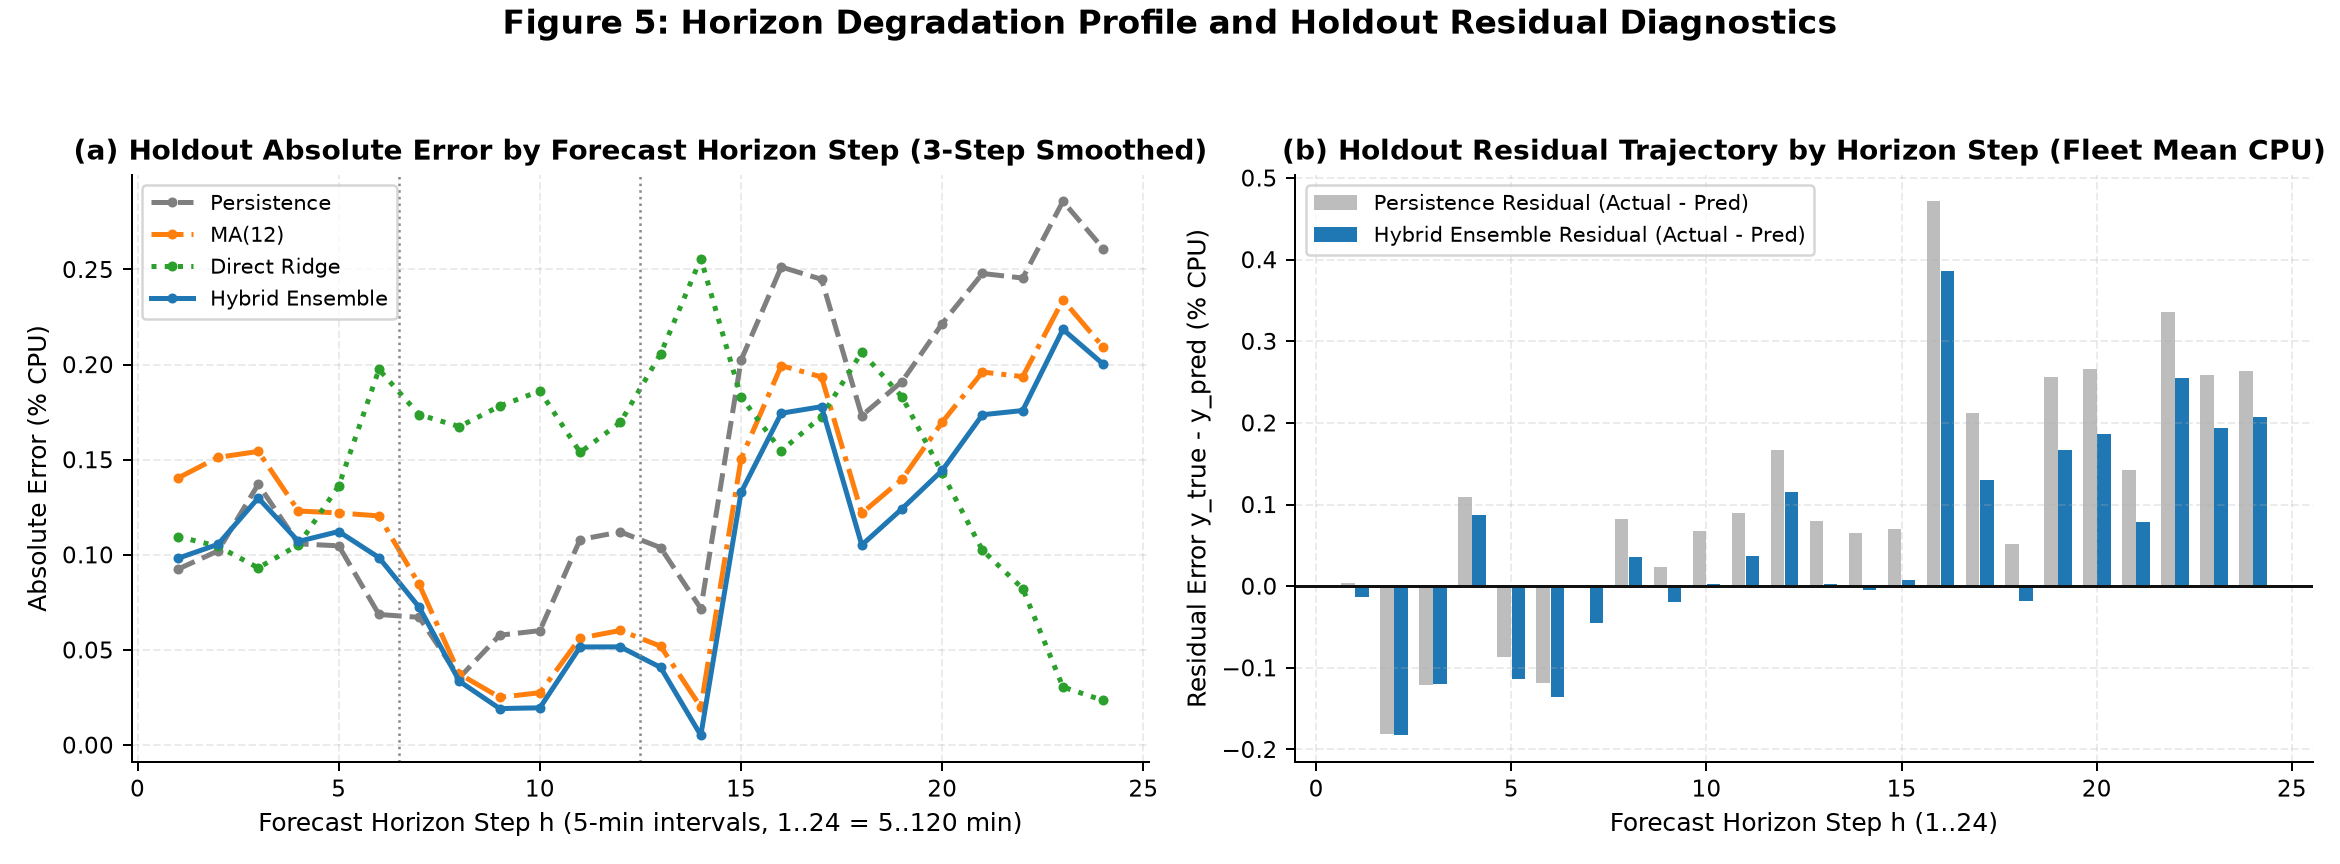

In [3]:
# Top-Down vs Bottom-Up Stratum & VM Shrinkage Reconciliation + Horizon Decay
reconcil_df = pd.read_csv(TABLES_DIR / 'reconciliation_comparison.csv')
horizon_df = pd.read_csv(TABLES_DIR / 'horizon_decay_metrics.csv')
print('=== Top-Down vs Bottom-Up Reconciliation (fleet_avg_cpu) ===')
display(reconcil_df.sort_values('holdout_mae').round(4))
print('=== Horizon Error Decay (fleet_avg_cpu) ===')
display(horizon_df[horizon_df['target'] == 'fleet_avg_cpu'].pivot(index='model_label', columns='horizon_bucket', values='mae').round(4))
display(Image(filename='../reports/figures/fig4_holdout_forecasts_with_intervals.png'))
display(Image(filename='../reports/figures/fig5_error_by_horizon_and_residuals.png'))

=== Empirical Holdout Interval Coverage ===


,target,bound,nominal,empirical_coverage,mean_width,pinball_loss
0,fleet_avg_cpu,p80_upper,0.80,0.9583,0.3258,0.0552
1,fleet_avg_cpu,p90_upper,0.90,1.0000,0.4621,0.0411
2,fleet_avg_cpu,p95_upper,0.95,1.0000,0.5430,0.0246
3,fleet_avg_cpu,pi80,0.80,1.0000,0.8141,NaN
4,fleet_avg_cpu,pi90,0.90,1.0000,1.0318,NaN
5,fleet_p95_max_cpu,p80_upper,0.80,1.0000,6.1370,1.1687
6,fleet_p95_max_cpu,p90_upper,0.90,1.0000,8.1364,0.7843
7,fleet_p95_max_cpu,p95_upper,0.95,1.0000,11.2759,0.5491
8,fleet_p95_max_cpu,pi80,0.80,1.0000,14.9120,NaN
9,fleet_p95_max_cpu,pi90,0.90,1.0000,21.5398,NaN


=== Operational Capacity Policy Simulation (28,396 Provisioned vCores) ===


,scenario,policy,mean_provisioned_pct,mean_provisioned_cores,sla_violations,sla_violation_rate_pct,mean_shortfall_pct,max_shortfall_pct,mean_overprovision_pct,mean_shortfall_cores,mean_overprovision_cores,asymmetric_cost,is_recommended
0,Standard 5-Min Mean Demand,Point Forecast (No Headroom),9.2174,2617.3787,15,62.5000,0.0788,0.3856,0.0273,22.3871,7.7440,0.4215,False
1,Standard 5-Min Mean Demand,Static Safety Margin (+5% relative),9.6783,2748.2476,0,0.0000,0.0000,0.0000,0.4093,0.0000,116.2259,0.4093,False
2,Standard 5-Min Mean Demand,Static Safety Margin (+10% relative),10.1392,2879.1166,0,0.0000,0.0000,0.0000,0.8702,0.0000,247.0948,0.8702,False
3,Standard 5-Min Mean Demand,Horizon-Adaptive P80 Upper Bound,9.5432,2709.8995,1,4.1667,0.0003,0.0074,0.2746,0.0872,77.9649,0.2761,False
4,Standard 5-Min Mean Demand,Horizon-Adaptive P90 Upper Bound (Recommended),9.6795,2748.5877,0,0.0000,0.0000,0.0000,0.4105,0.0000,116.5659,0.4105,True
5,Standard 5-Min Mean Demand,Horizon-Adaptive P95 Upper Bound (Conservative),9.7604,2771.5761,0,0.0000,0.0000,0.0000,0.4915,0.0000,139.5544,0.4915,False
6,Burst Stress-Test (+5% Intra-Window Surge),Point Forecast (No Headroom),9.2174,2617.3787,24,100.0000,0.5150,0.8674,0.0000,146.2441,0.0000,2.5751,False
7,Burst Stress-Test (+5% Intra-Window Surge),Static Safety Margin (+5% relative),9.6783,2748.2476,15,62.5000,0.0828,0.4049,0.0286,23.5064,8.1312,0.4425,False
8,Burst Stress-Test (+5% Intra-Window Surge),Static Safety Margin (+10% relative),10.1392,2879.1166,0,0.0000,0.0000,0.0000,0.4067,0.0000,115.4937,0.4067,False
9,Burst Stress-Test (+5% Intra-Window Surge),Horizon-Adaptive P80 Upper Bound,9.5432,2709.8995,24,100.0000,0.1892,0.4892,0.0000,53.7234,0.0000,0.9460,False


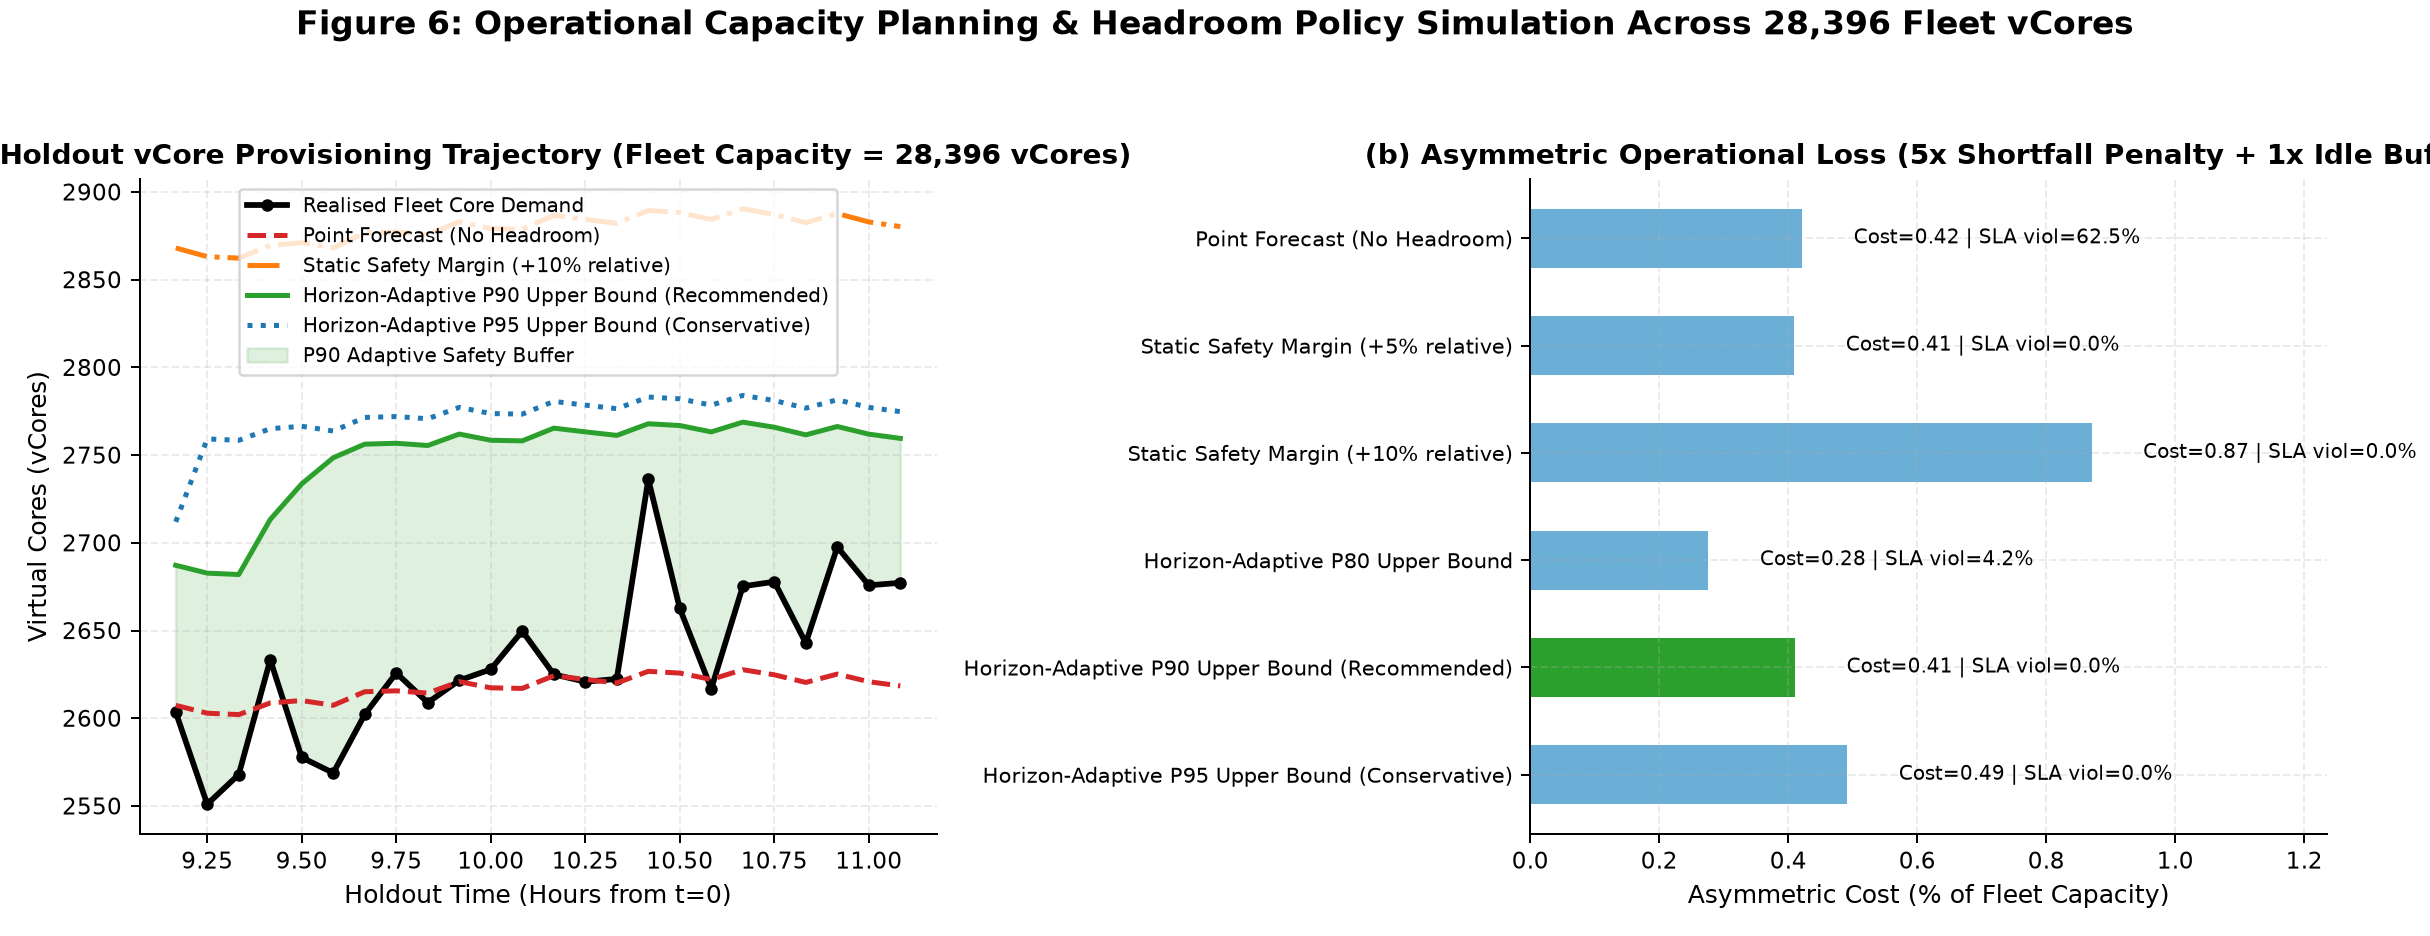

In [4]:
# Conformalized Empirical Interval Coverage & vCore Capacity Policy Simulation (28,396 vCores)
cov_df = pd.read_csv(TABLES_DIR / 'interval_coverage.csv')
pol_df = pd.read_csv(TABLES_DIR / 'capacity_policy.csv')
print('=== Empirical Holdout Interval Coverage ===')
display(cov_df.round(4))
print('=== Operational Capacity Policy Simulation (28,396 Provisioned vCores) ===')
display(pol_df.round(4))
display(Image(filename='../reports/figures/fig6_capacity_headroom_policy.png'))